<a href="https://colab.research.google.com/github/AslanZeinalov/Bike-store-analysis/blob/main/bike_store_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Аналитика веломагазина

## Бизнес-контекст

### Цель проекта
Проанализировать данные сети веломагазинов (2016-2018) и найти точки роста выручки.

### Ключевые вопросы:
1. Как меняется выручка во времени? Есть ли сезонность?
2. Какие категории товаров приносят больше всего денег?
3. Сколько денег мы теряем из-за дефицита товаров?
4. Кто наши лучшие клиенты и как удержать остальных?

### Стек:
Python, SQL, pandas, matplotlib

## 1. Импорт библиотек и загрузка данных

In [1]:
import kagglehub
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

path = kagglehub.dataset_download("dillonmyrick/bike-store-sample-database")

print("Path to dataset files:", path)

100%|██████████| 92.2k/92.2k [00:00<00:00, 606kB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/dillonmyrick/bike-store-sample-database/versions/3


In [2]:
!ls /root/.cache/kagglehub/datasets/dillonmyrick/bike-store-sample-database/versions/3

brands.csv	customers.csv	 orders.csv    staffs.csv  stores.csv
categories.csv	order_items.csv  products.csv  stocks.csv


In [3]:
brands = pd.read_csv(path + '/brands.csv')
customers = pd.read_csv(path + '/customers.csv')
orders = pd.read_csv(path + '/orders.csv')
staffs = pd.read_csv(path + '/staffs.csv')
stores = pd.read_csv(path + '/stores.csv')
categories = pd.read_csv(path + '/categories.csv')
order_items = pd.read_csv(path + '/order_items.csv')
products = pd.read_csv(path + '/products.csv')
stocks = pd.read_csv(path + '/stocks.csv')




In [4]:
tables = [brands, customers, orders, staffs, stores, categories, order_items, products, stocks]


## 2. EDA

### Структура таблиц:

In [5]:
for table in tables:
  print(table.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   brand_id    9 non-null      int64 
 1   brand_name  9 non-null      object
dtypes: int64(1), object(1)
memory usage: 276.0+ bytes
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1445 entries, 0 to 1444
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   customer_id  1445 non-null   int64 
 1   first_name   1445 non-null   object
 2   last_name    1445 non-null   object
 3   phone        178 non-null    object
 4   email        1445 non-null   object
 5   street       1445 non-null   object
 6   city         1445 non-null   object
 7   state        1445 non-null   object
 8   zip_code     1445 non-null   int64 
dtypes: int64(2), object(7)
memory usage: 101.7+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1615 entries, 0 

### Пропуски:

In [6]:
for table in tables:
    missing = table.isna().sum()
    missing = missing[missing > 0]
    if not missing.empty:
        print(f"\n{missing}")


phone    1267
dtype: int64

shipped_date    170
dtype: int64

manager_id    1
dtype: int64


Заменим пропущенные значения в phone на строку "Не указан":

In [7]:
customers['phone'] = customers['phone'].fillna('Не указан')
customers.isna().sum()

,0
customer_id,0
first_name,0
last_name,0
phone,0
email,0
street,0
city,0
state,0
zip_code,0


Проверим причины пропусков в shipped_date:

In [8]:
orders[orders['shipped_date'].isna()]

,order_id,customer_id,order_status,order_date,required_date,shipped_date,store_id,staff_id
69,70,50,3,2016-02-11,2016-02-11,NaN,3,9
75,76,9,3,2016-02-16,2016-02-16,NaN,2,6
157,158,117,3,2016-04-04,2016-04-04,NaN,3,9
184,185,24,3,2016-04-20,2016-04-20,NaN,1,2
238,239,13,3,2016-05-27,2016-05-27,NaN,3,9
...,...,...,...,...,...,...,...,...
1610,1611,6,3,2018-09-06,2018-09-06,NaN,2,7
1611,1612,3,3,2018-10-21,2018-10-21,NaN,1,3
1612,1613,1,3,2018-11-18,2018-11-18,NaN,2,6
1613,1614,135,3,2018-11-28,2018-11-28,NaN,3,8


Проверим распределение статусов заказа при пустом значнии shipped_date:

In [9]:
orders[orders['shipped_date'].isna()]['order_status'].value_counts()

,count
order_status,
2,63
1,62
3,45


Значения статусов:

1 = Pending (Ожидает подтверждения/оплаты)

2 = Processing (В обработке/собирается на складе)

3 = Rejected / Cancelled (Отменен или отклонен)

4 = Completed / Shipped (Завершен / Отправлен)

Проверим в какое время были данные заказы:

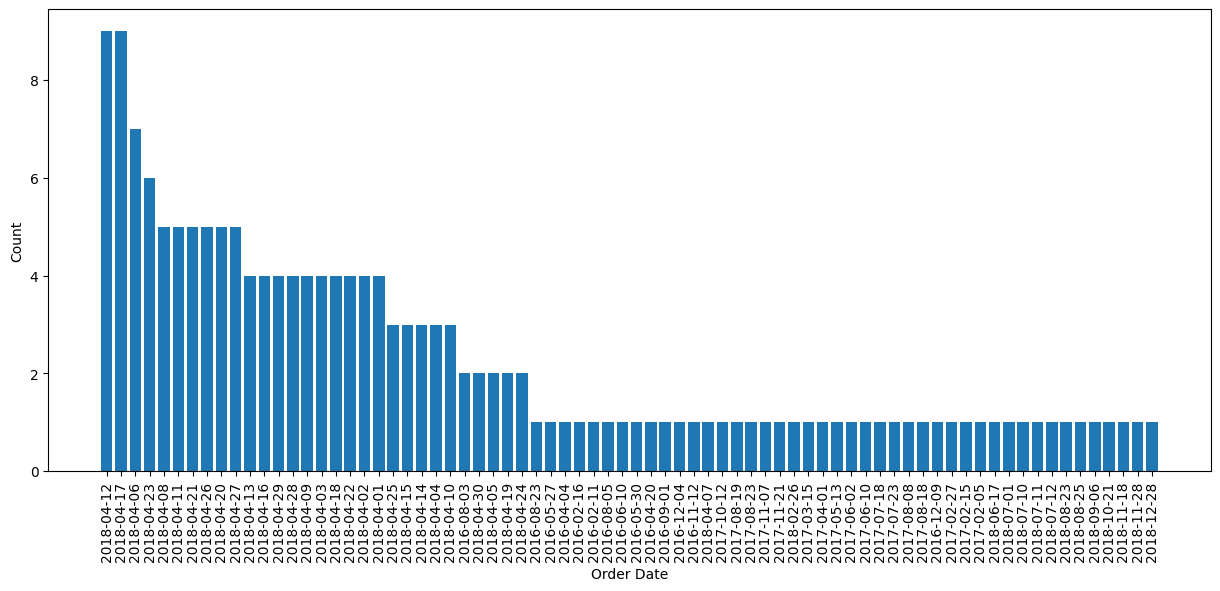

In [10]:
import matplotlib.pyplot as plt

missing_shipped_date = orders[orders['shipped_date'].isna()]
missing_shipped_date_by_dates = missing_shipped_date.groupby('order_date').agg(count=('order_id', 'count')).sort_values('count', ascending=False)

plt.figure(figsize=(15, 6))
plt.bar(missing_shipped_date_by_dates.index.astype(str), missing_shipped_date_by_dates['count'])
plt.xticks(rotation=90)
plt.xlabel('Order Date')
plt.ylabel('Count')
plt.show()

### Гипотеза

Видим, что большая часть отмененных заказов сосредоточена в апреле 2018 года. Можно сделать предположение, что отмены заказов связаны с нехваткой товара на складе. Возможно данный период является пиковым по продажам, т.к. покупатели готовятся к открытию сезона катания. Далее проверим распределение выручки по времени что бы подтвердить данную гипотезу.

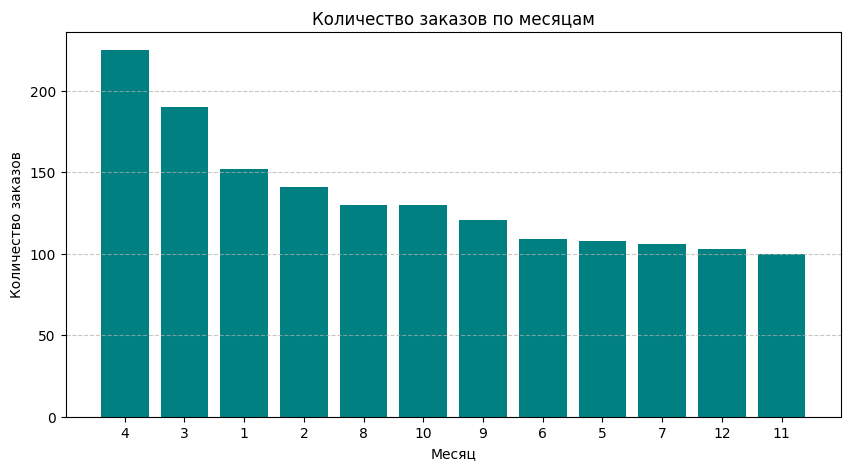

In [11]:
temp_df = pd.merge(orders, order_items, on='order_id')
temp_df['discount_price'] = temp_df['list_price'] - temp_df['list_price'] * temp_df['discount']
temp_df['order_date'] = pd.to_datetime(temp_df['order_date'])
temp_df['year'] = temp_df['order_date'].dt.year
temp_df['month'] = temp_df['order_date'].dt.month

monthly_orders = temp_df.groupby('month', as_index=False).agg(order_count=('order_id', 'nunique'))

monthly_orders = monthly_orders.sort_values('order_count', ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(monthly_orders['month'].astype(str), monthly_orders['order_count'], color='teal')
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')
plt.title('Количество заказов по месяцам')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Пик продаж приходится на март и апрель, как и предполагалось. Расчитаем упущенную прибыль из-за нехватки товара.

In [12]:
missing_revenue = temp_df[temp_df['month'].isin([3, 4])]['discount_price'].sum()
print(f"Упущенная прибыль из-за нехватки товара в ежегодный пик продаж: {missing_revenue:.2f}")

avg_year_revenue = temp_df[temp_df['year'].isin([2016, 2017])].groupby('year')['discount_price'].sum().mean()
print(f"Средняя выручка за 2016, 2017 год: {avg_year_revenue:.2f}")
print(f"Доля от общей среднегодовой выручки: {missing_revenue / avg_year_revenue:.2f}")

Упущенная прибыль из-за нехватки товара в ежегодный пик продаж: 1377073.44
Средняя выручка за 2016, 2017 год: 1957321.56
Доля от общей среднегодовой выручки: 0.70


Таким образом мы нашли причину просадки выручки в 2018 году. Составим список проблемных товаров:

In [13]:
high_demand_item = temp_df[(temp_df['year'] == 2018) & (temp_df['month'] == 4) & (temp_df['shipped_date'].isna())].groupby('item_id', as_index=False).agg(count=('item_id', 'count')).sort_values('count', ascending=False)
high_demand_item

,item_id,count
0,1,125
1,2,103
2,3,74
3,4,50
4,5,33


Теперь удалим отмененные заказы из нашей таблицы для корректности дальнейшего анализа:

In [14]:
orders = orders[orders['shipped_date'].notna()]
orders.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_date,0
required_date,0
shipped_date,0
store_id,0
staff_id,0


В таблице заказов создадим столбец цены с учетом скидки:

In [15]:
order_items['price'] = order_items['list_price'] - order_items['list_price'] * order_items['discount']
order_items.head(1)

,order_id,item_id,product_id,quantity,list_price,discount,price
0,1,1,20,1,599.99,0.2,479.992


Загрузим подготовленные таблицы в общую базу данных sqlite, для использования SQL-запросов

In [16]:
connection = sqlite3.connect('bike_store.db')

brands.to_sql('brands', connection, if_exists='replace', index=False)
customers.to_sql('customers', connection, if_exists='replace', index=False)
orders.to_sql('orders', connection, if_exists='replace', index=False)
staffs.to_sql('staffs', connection, if_exists='replace', index=False)
stores.to_sql('stores', connection, if_exists='replace', index=False)
categories.to_sql('categories', connection, if_exists='replace', index=False)
order_items.to_sql('order_items', connection, if_exists='replace', index=False)
products.to_sql('products', connection, if_exists='replace', index=False)
stocks.to_sql('stocks', connection, if_exists='replace', index=False);

### Основная статистика:

In [17]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)

#Кол-во персонала
query = '''
SELECT COUNT(staff_id)
FROM staffs
'''
nstaff = pd.read_sql(query, connection).iloc[0, 0]

# Уникальные клиенты

query = '''
SELECT COUNT(customer_id)
FROM customers
'''
ncustomers = pd.read_sql(query, connection).iloc[0, 0]

# Магазины

query = '''
SELECT COUNT(store_id)
FROM stores
'''
nstores = pd.read_sql(query, connection).iloc[0, 0]

# Категории

query = '''
SELECT COUNT(category_id)
FROM categories
'''
categories_count = pd.read_sql(query, connection).iloc[0, 0]

# Товаров

query = '''
SELECT COUNT(product_id)
FROM products
'''
nproducts = pd.read_sql(query, connection).iloc[0, 0]

# Выручка с учетом скидок

query = '''
SELECT SUM(price * quantity)
FROM order_items
'''
revenue = pd.read_sql(query, connection).iloc[0, 0]

# Скидки

query = '''
SELECT SUM(discount * price * quantity)
FROM order_items
'''
discount = pd.read_sql(query, connection).iloc[0, 0]

# Заказы

query = '''
SELECT COUNT(order_id)
FROM orders
'''
orders_count = pd.read_sql(query, connection).iloc[0, 0]

# Создаем итоговый датафрейм из полученных скалярных значений
stat = pd.DataFrame(
    [nstaff, ncustomers, nstores, categories_count, nproducts, revenue, discount, orders_count],
    columns=['Значение'],
    index=['Кол-во персонала', 'Уникальные клиенты', 'Магазины', 'Категории', 'Товаров', 'Выручка с учетом скидок', 'Скидки', 'Заказы']
)
stat

,Значение
Кол-во персонала,10.00
Уникальные клиенты,1445.00
Магазины,3.00
Категории,7.00
Товаров,321.00
Выручка с учетом скидок,7689116.56
Скидки,769109.63
Заказы,1445.00


## 3. Временной анализ

In [18]:
query = '''
SELECT
    strftime('%Y', order_date) AS year,
    strftime('%m', order_date) AS month,
    strftime('%d', order_date) AS day,
    strftime('%w', order_date) AS day_of_week,
    SUM(price * quantity) AS revenue
FROM orders O
JOIN order_items oi USING(order_id)
GROUP BY year, month, day
ORDER BY year, month, day
'''

time_df = pd.read_sql(query, connection)
time_df.head(10)

,year,month,day,day_of_week,revenue
0,2016,01,01,5,11929.02
1,2016,01,02,6,1519.98
2,2016,01,03,0,5250.04
3,2016,01,04,1,12980.06
4,2016,01,05,2,10598.93
5,2016,01,06,3,6816.92
6,2016,01,08,5,3278.05
7,2016,01,09,6,4467.15
8,2016,01,12,2,6542.61
9,2016,01,14,4,23318.11


In [19]:
time_df['month'] = time_df['month'].map({
    '01': 'Январь',
    '02': 'Февраль',
    '03': 'Март',
    '04': 'Апрель',
    '05': 'Май',
    '06': 'Июнь',
    '07': 'Июль',
    '08': 'Август',
    '09': 'Сентябрь',
    '10': 'Октябрь',
    '11': 'Ноябрь',
    '12': 'Декабрь'
})

time_df['day_of_week'] = time_df['day_of_week'].map({
    '0': 'Понедельник',
    '1': 'Вторник',
    '2': 'Среда',
    '3': 'Четверг',
    '4': 'Пятница',
    '5': 'Суббота',
    '6': 'Воскресенье'
})

time_df.head(3)

,year,month,day,day_of_week,revenue
0,2016,Январь,01,Суббота,11929.02
1,2016,Январь,02,Воскресенье,1519.98
2,2016,Январь,03,Понедельник,5250.04


Выручка годам:

In [20]:
year_revenue = time_df.groupby('year', as_index=False).agg(revenue=('revenue', 'sum'))
month_revenue = time_df.groupby('month', as_index=False).agg(revenue=('revenue', 'sum')).sort_values('month')
day_revenue = time_df.groupby('day', as_index=False).agg(revenue=('revenue', 'sum'))
day_of_week_revenue = time_df.groupby('day_of_week', as_index=False).agg(revenue=('revenue', 'sum'))

Text(0.5, 1.0, 'Выручка по годам')

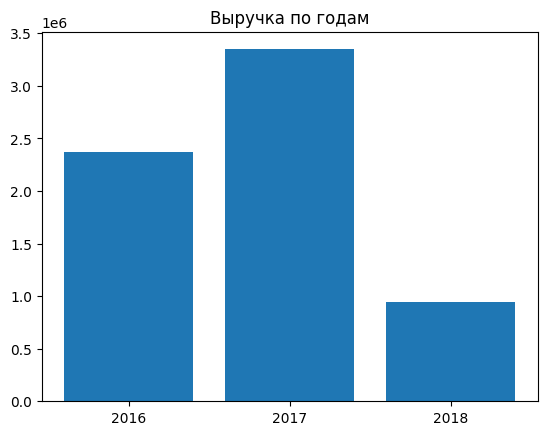

In [21]:
import matplotlib.pyplot as plt

plt.bar(year_revenue['year'], year_revenue['revenue'])
plt.title('Выручка по годам')

Причину снижения выручки в 2018 году мы уже определили  - нехватка товарного запаса в сезон пиковых продаж

Распределение выручки по месяцам:

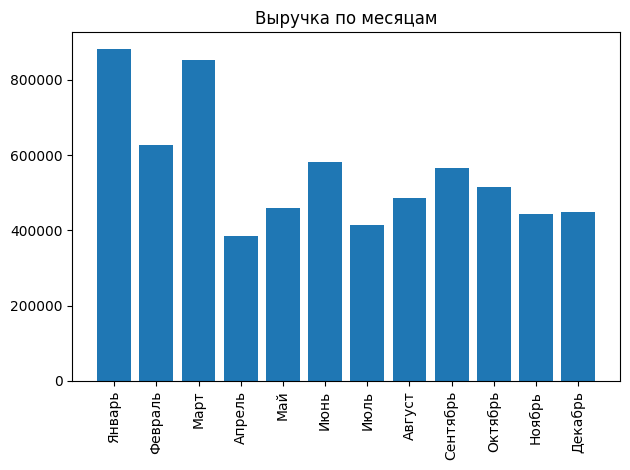

In [22]:
months_order = ['Январь', 'Февраль', 'Март', 'Апрель', 'Май', 'Июнь', 'Июль', 'Август', 'Сентябрь', 'Октябрь', 'Ноябрь', 'Декабрь']
month_revenue['month'] = pd.Categorical(month_revenue['month'], categories=months_order, ordered=True)
month_revenue = month_revenue.sort_values('month')

plt.bar(month_revenue['month'], month_revenue['revenue'])
plt.xticks(rotation=90)
plt.title('Выручка по месяцам')
plt.tight_layout()

## 4. Товарная аналитика и структура категорий

Выручка по категориям:

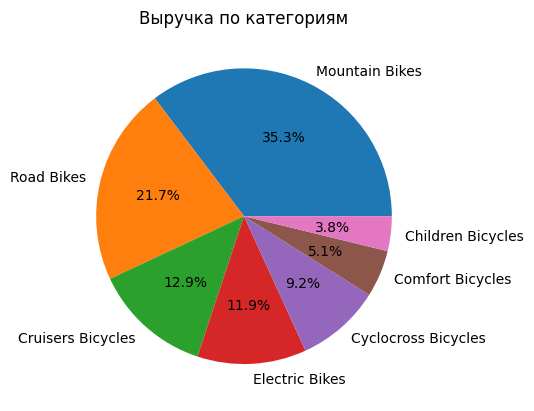

In [23]:
query = '''
SELECT
    c.category_name,
    SUM(oi.price * oi.quantity) AS revenue
FROM order_items oi
JOIN products p USING(product_id)
JOIN categories c USING(category_id)
GROUP BY c.category_id, c.category_name
ORDER BY revenue DESC
'''

revenue_by_category = pd.read_sql(query, connection)

plt.pie(revenue_by_category['revenue'], labels=revenue_by_category['category_name'], autopct='%1.1f%%')
plt.title('Выручка по категориям')
plt.show()

Топ товаров по выручке:

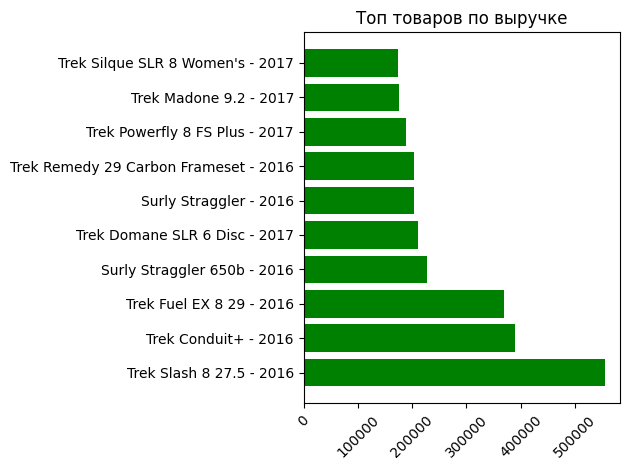

In [24]:
query = '''
SELECT
    p.product_name,
    SUM(oi.price * oi.quantity) AS revenue
FROM order_items oi
JOIN products p USING(product_id)
GROUP BY p.product_id, p.product_name
ORDER BY revenue DESC
LIMIT 10
'''

hit_sales = pd.read_sql(query, connection)

plt.barh(hit_sales['product_name'], hit_sales['revenue'], color='green')
plt.xticks(rotation=45)
plt.title('Топ товаров по выручке')
plt.tight_layout()

Худшие товары по выручке:

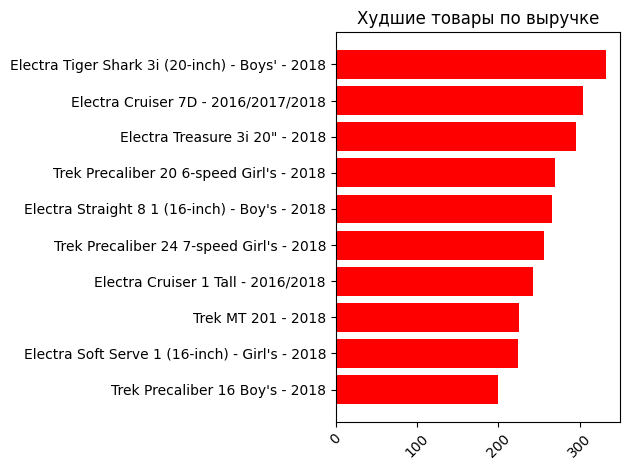

In [25]:
query = '''
SELECT
    p.product_name,
    SUM(oi.price * oi.quantity) AS revenue
FROM order_items oi
JOIN products p USING(product_id)
GROUP BY p.product_id, p.product_name
ORDER BY revenue ASC
LIMIT 10
'''

bottom_sales = pd.read_sql(query, connection)

plt.barh(bottom_sales['product_name'], bottom_sales['revenue'], color='red')
plt.xticks(rotation=45)
plt.title('Худшие товары по выручке')
plt.tight_layout()

Найдем 20% товаров дающих 80% выручки(Принцип Парето)

In [26]:
query = '''
SELECT
    p.product_name,
    SUM(oi.price * oi.quantity) AS revenue
FROM order_items oi
JOIN products p USING(product_id)
GROUP BY p.product_id, p.product_name
ORDER BY revenue DESC
'''

item_revenue = pd.read_sql(query, connection)

total_revenue = item_revenue['revenue'].sum()
item_revenue['revenue_share'] = item_revenue['revenue'] / total_revenue * 100
item_revenue['cumulative_revenue'] = item_revenue['revenue'].cumsum()
item_revenue['cumulative_share'] = item_revenue['cumulative_revenue'] / total_revenue * 100
item_revenue['product_rank'] = range(1, len(item_revenue) + 1)
item_revenue['cumulative_product_share'] = item_revenue['product_rank'] / len(item_revenue) * 100

pareto_threshold = 80
pareto_products = item_revenue[item_revenue['cumulative_share'] <= pareto_threshold]
n_pareto = len(pareto_products)
non_pareto_products = item_revenue[item_revenue['cumulative_share'] > pareto_threshold]
pareto_pct = n_pareto / nproducts * 100

print(f"   Всего товаров: {nproducts}")
print(f"   Товаров, дающих 80% выручки: {n_pareto} ({pareto_pct:.1f}%)")
print(f"   Выручка этих товаров: ${pareto_products['revenue'].sum():,.0f}")

   Всего товаров: 321
   Товаров, дающих 80% выручки: 68 (21.2%)
   Выручка этих товаров: $6,132,683


In [27]:
pareto_products

,product_name,revenue,revenue_share,cumulative_revenue,cumulative_share,product_rank,cumulative_product_share
0,Trek Slash 8 27.5 - 2016,555558.61,7.23,555558.61,7.23,1,0.33
1,Trek Conduit+ - 2016,389248.70,5.06,944807.31,12.29,2,0.65
2,Trek Fuel EX 8 29 - 2016,368472.73,4.79,1313280.04,17.08,3,0.98
3,Surly Straggler 650b - 2016,226765.55,2.95,1540045.59,20.03,4,1.30
4,Trek Domane SLR 6 Disc - 2017,211584.62,2.75,1751630.21,22.78,5,1.63
...,...,...,...,...,...,...,...
63,Surly Wednesday - 2017,26438.11,0.34,6034825.27,78.49,64,20.85
64,Trek Super Commuter+ 7 - 2018,25847.93,0.34,6060673.20,78.82,65,21.17
65,Trek Emonda SLR 8 - 2018,24179.96,0.31,6084853.16,79.14,66,21.50
66,Trek XM700+ - 2018,24149.93,0.31,6109003.09,79.45,67,21.82


Данные товары всегда должны быть в наличии, так как из них складывается основная выручка. Стоит рассмотреть вывод из ассортимента товаров с крайне низкими продажами, для оптимизации складского пространства. Также можно провести A/B тестирование снижения размера скидок для хитов продаж и оценить как это повлияет на колличество заказов.

## 5. Магазины

Выручка по магазинам:

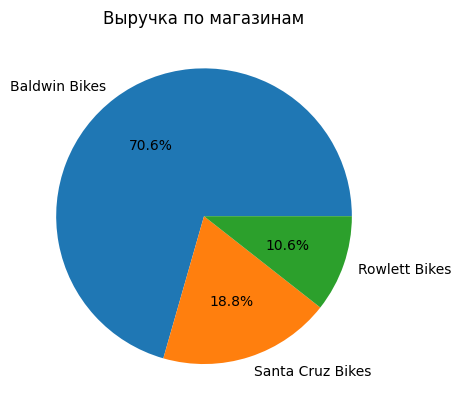

In [28]:
query = '''
SELECT SUM(oi.price * oi.quantity) AS revenue, s.store_name
FROM order_items oi
JOIN orders o USING(order_id)
JOIN stores s USING(store_id)
GROUP BY s.store_id, s.store_name
ORDER BY revenue DESC
'''

revenue_by_store = pd.read_sql(query, connection)

plt.pie(revenue_by_store['revenue'], labels=revenue_by_store['store_name'], autopct='%1.1f%%')
plt.title('Выручка по магазинам')
plt.show()

Магазин BaldwinBikes приносит 70% выручки. Нужно выяснить в чем причина такой сильной разницы с другими магизинами.

Заказы по магазинам:

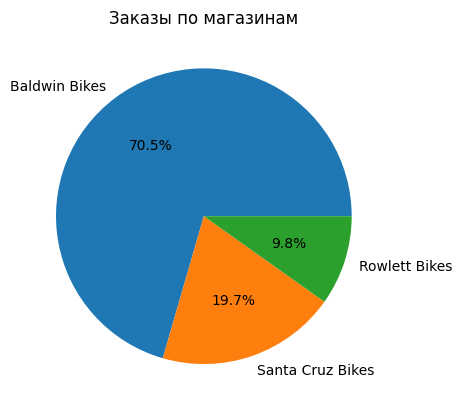

In [29]:
query = '''
SELECT COUNT(o.order_id) AS orders, s.store_name
FROM orders o
JOIN stores s USING(store_id)
GROUP BY s.store_id, s.store_name
ORDER BY orders DESC
'''

orders_by_stores = pd.read_sql(query, connection)

plt.pie(orders_by_stores['orders'], labels=orders_by_stores['store_name'], autopct='%1.1f%%')
plt.title('Заказы по магазинам')
plt.show()

Средний чек по магазинам:

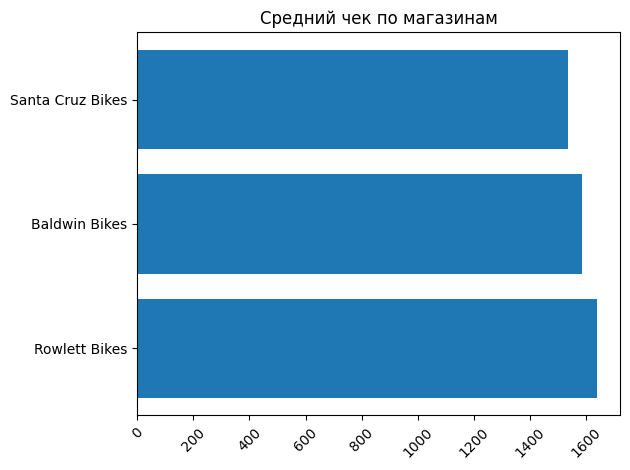

In [30]:
query = '''
SELECT AVG(oi.price * oi.quantity) AS avg_check, s.store_name
FROM order_items oi
JOIN orders o USING(order_id)
JOIN stores s USING(store_id)
GROUP BY s.store_id, s.store_name
ORDER BY avg_check DESC
'''

avg_check_by_stores = pd.read_sql(query, connection)
plt.barh(avg_check_by_stores['store_name'], avg_check_by_stores['avg_check'])
plt.xticks(rotation=45)
plt.title('Средний чек по магазинам')
plt.tight_layout()

In [31]:
query = '''
SELECT store_name, state
FROM stores
'''

stores = pd.read_sql(query, connection)
stores

,store_name,state
0,Santa Cruz Bikes,CA
1,Baldwin Bikes,NY
2,Rowlett Bikes,TX


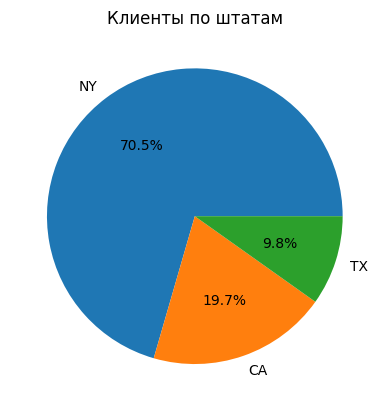

In [32]:
query = '''
SELECT state, COUNT(customer_id) as customers
FROM customers
GROUP BY state
ORDER BY customers DESC
'''

customers_by_state = pd.read_sql(query, connection)
plt.pie(customers_by_state['customers'], labels=customers_by_state['state'], autopct='%1.1f%%')
plt.title('Клиенты по штатам')
plt.show()

Лидирующий магазин находится в NY, крупном мегаполисе. С этим сязано, что большее колличество клиентов и выручки сосредоточено здесь. Данную информацию можно исползовать для оптимизации логистических маршрутов и расположения складов для снижения логистических издержек и увеличения маржинальности.

## 6. Работа сотрудников

In [34]:
query = """
WITH order_summary AS (
    SELECT
        o.order_id,
        o.staff_id,
        SUM(oi.quantity) AS items_in_order,
        SUM(oi.quantity * oi.list_price * (1 - oi.discount)) AS order_revenue,
        COUNT(oi.item_id) AS unique_items
    FROM orders o
    JOIN order_items oi USING(order_id)
    WHERE o.order_status = 4
    GROUP BY o.order_id, o.staff_id
)
SELECT
    s.staff_id,
    s.first_name || ' ' || s.last_name AS staff_name,
    st.store_name,
    COUNT(os.order_id) AS total_orders,
    ROUND(AVG(os.items_in_order), 2) AS avg_items_per_order,
    ROUND(AVG(os.order_revenue), 2) AS avg_order_value,
    ROUND(SUM(os.order_revenue), 2) AS total_revenue
FROM order_summary os
JOIN staffs s USING(staff_id)
JOIN stores st USING(store_id)
GROUP BY s.staff_id, s.first_name, s.last_name, st.store_name
ORDER BY avg_items_per_order DESC
"""

staff_performance = pd.read_sql(query, connection)
staff_performance

,staff_id,staff_name,store_name,total_orders,avg_items_per_order,avg_order_value,total_revenue
0,8,Kali Vargas,Rowlett Bikes,71,4.83,5288.24,375464.80
1,3,Genna Serrano,Santa Cruz Bikes,147,4.52,4378.42,643627.98
2,7,Venita Daniel,Baldwin Bikes,498,4.39,4610.43,2295991.72
3,9,Layla Terrell,Rowlett Bikes,71,4.39,4654.21,330449.23
4,6,Marcelene Boyer,Baldwin Bikes,521,4.31,4616.54,2405217.85
5,2,Mireya Copeland,Santa Cruz Bikes,137,4.18,4466.16,611863.67


## 7. RFM-анализ клиентов

Проведем RFM-анализ клиентов: Recency (давность), Frequency (частота), Monetary (деньги)

Распределение клиентов по RFM-сегментам:


,customers_count,avg_frequency,avg_monetary,total_revenue,%_of_customers,%_of_revenue
segment,,,,,,
Champions,382,1.00,8313.69,3175830.07,26.40,47.70
At Risk,340,1.00,6653.23,2262099.01,23.50,34.00
Hibernating,383,1.00,1729.38,662353.05,26.50,9.90
Loyal Customers,163,1.00,2479.85,404216.22,11.30,6.10
New Customers,177,1.00,893.31,158115.62,12.20,2.40


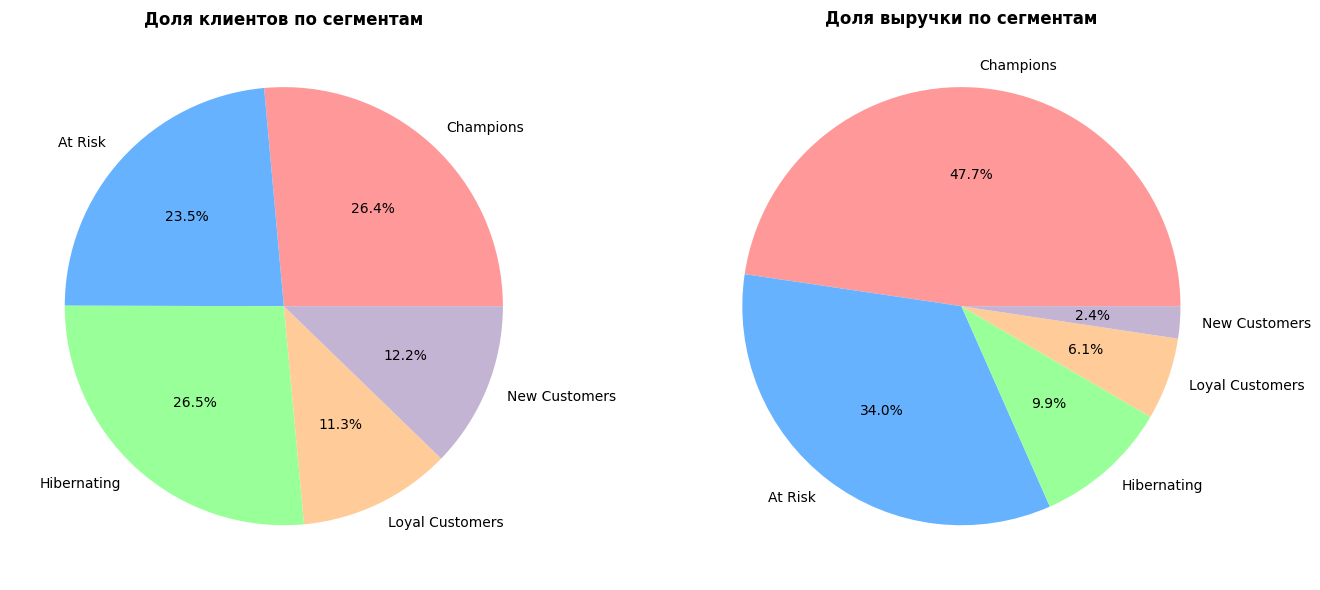

In [54]:
query_rfm = '''
WITH customer_rfm AS (
    SELECT
        o.customer_id,
        MAX(o.order_date) AS last_purchase_date,
        COUNT(DISTINCT o.order_id) AS frequency,
        SUM(oi.quantity * oi.price) AS monetary
    FROM orders o
    JOIN order_items oi USING(order_id)
    GROUP BY o.customer_id
),
rfm_scores AS (
    SELECT
        customer_id,
        frequency,
        monetary,
        NTILE(4) OVER (ORDER BY CAST(julianday('2019-01-01') - julianday(last_purchase_date) AS INT) DESC) AS r_score,
        NTILE(4) OVER (ORDER BY frequency ASC) AS f_score,
        NTILE(4) OVER (ORDER BY monetary ASC) AS m_score
    FROM customer_rfm
)
SELECT
    customer_id,
    frequency,
    ROUND(monetary, 2) AS monetary,
    r_score,
    f_score,
    m_score,
    (r_score + f_score + m_score) AS rfm_total_score,
    CASE
        WHEN r_score >= 3 AND f_score >= 3 AND m_score >= 3 THEN 'Champions'
        WHEN r_score >= 3 AND f_score >= 2 AND m_score >= 2 THEN 'Loyal Customers'
        WHEN r_score >= 3 AND f_score <= 2 THEN 'New Customers'
        WHEN r_score <= 2 AND f_score >= 3 AND m_score >= 3 THEN 'At Risk'
        WHEN r_score <= 2 AND f_score <= 2 THEN 'Hibernating'
        ELSE 'Potential Loyalists'
    END AS segment
FROM rfm_scores
ORDER BY rfm_total_score DESC
'''

rfm_df = pd.read_sql(query_rfm, connection)

segment_stats = rfm_df.groupby('segment').agg(
    customers_count=('customer_id', 'count'),
    avg_frequency=('frequency', 'mean'),
    avg_monetary=('monetary', 'mean'),
    total_revenue=('monetary', 'sum')
).round(2)

segment_stats['%_of_customers'] = (segment_stats['customers_count'] / segment_stats['customers_count'].sum() * 100).round(1)
segment_stats['%_of_revenue'] = (segment_stats['total_revenue'] / segment_stats['total_revenue'].sum() * 100).round(1)
segment_stats = segment_stats.sort_values('total_revenue', ascending=False)

print("Распределение клиентов по RFM-сегментам:")
display(segment_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].pie(
    segment_stats['customers_count'],
    labels=segment_stats.index,
    autopct='%1.1f%%',
    colors=['#FF9999','#66B2FF','#99FF99','#FFCC99', '#c4b4d4', '#ff9999']
)
axes[0].set_title('Доля клиентов по сегментам', fontsize=12, fontweight='bold')

axes[1].pie(
    segment_stats['total_revenue'],
    labels=segment_stats.index,
    autopct='%1.1f%%',
    colors=['#FF9999','#66B2FF','#99FF99','#FFCC99', '#c4b4d4', '#ff9999']
)
axes[1].set_title('Доля выручки по сегментам', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

**Champions** - Самая ценная группа клиентов. Покупают часто, тратят много и делали покупки недавно

**At Risk** - Клиенты, которые раньше активно покупали и тратили значительные суммы, но недавно перестали совершать покупки

**Hibernating** - Клиенты, которые покупали редко, тратили немного и давно не совершали покупок

**Loyal Customers** - Стабильная группа, которая обеспечивает постоянный денежный поток, но не является основным источником выручки.

**New Customers** - Клиенты, которые совершили первую покупку недавно

## Итоговые рекомендации:

На основе проведенного анализа данных выявлены ключевые точки роста и проблемы. Ниже представлены приоритезированные рекомендации для руководства.

### Критический приоритет
1. **Оптимизация складских запасов перед пиковым сезоном**

   - **Проблема:** В апреле 2018 года упущенная выручка из-за дефицита составила: **$1.37 млн** (**70%** от среднегодовой выручки).

   - **Решение:** Увеличить страховой запас (safety stock) для 68 товаров, которые формируют 80% выручки (Принцип Парето), начиная с февраля. Настроить автоматические алерты при падении остатков ниже порогового значения.

   - **Ожидаемый эффект:** Возврат упущенной выручки +$500K - $800K в год.

### Высокий приоритет

2. **Оптимизация ассортимента (ABC-анализ)**
   - **Инсайт:** Выявлено более 50 позиций товаров с экстремально низкими продажами, которые занимают место на складе.
   - **Решение:** Провести распродажу (clearance sale) неликвидных товаров со скидкой 30-40% для высвобождения оборотных средств и складского пространства.
   - **Ожидаемый эффект:** Снижение затрат на хранение, улучшение оборачиваемости запасов.

### Среднесрочный приоритет
4. **Географическая и логистическая оптимизация**
   - **Инсайт:** Магазин Baldwin Bikes (NY) генерирует **70% выручки**, так как штат NY концентрирует основную массу клиентов.
   - **Решение:** Пересмотреть логистические маршруты поставок, чтобы приоритетно и быстрее доставлять товар именно в NY. Рассмотреть возможность открытия второго пункта выдачи или магазина в пределах штата NY для снятия нагрузки с Baldwin Bikes.

5. **Внедрение программы лояльности на основе RFM**
   - **Инсайт:** Сегмент "Champions" (топ-клиенты) генерирует непропорционально высокую долю выручки при малой численности. Сегмент "At Risk" (ранее активные, теперь не покупающие) требует внимания.
   - **Решение:**
     - Для "Champions": персональные предложения, ранний доступ к новым моделям, программа реферальных скидок.
     - Для "At Risk": автоматическая email-рассылка с промокодом на 15% через 60 дней после последней покупки.
   - **Ожидаемый эффект:** Увеличение LTV (пожизненной ценности клиента)